# Task 14, Notebook 10: Scoring audit, risk scores and Shapley explanations

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 14: Explain every person's risk  
**Objective:** Audit the 430-row scoring file, score it with attrition-v2, compute per-employee contributions and check how trustworthy they are.  
**Workflow stages covered in this notebook:** 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3 | seed: 42


## Stage 1: Business Understanding

*What this stage is for:* Who needs this result and what decision it supports.

A score alone cannot help an employee. HR needs to know what moved the score so a real conversation can start, and needs to see on every line that the number is a support signal and not a decision.

## Stage 2: Problem Definition

*What this stage is for:* The exact prediction, ranking or measurement problem, its inputs and its output.

**Input:** the 430 active employees at 30 Sep 2026. **Output:** one row per employee in the exact format of `sample_attrition_risk`: probability of leaving within 12 months, risk band, three plain-English reasons, model version, and a human-review note.

## Stage 3: Objective and Success Criteria

*What this stage is for:* What number or evidence shows the task is done well, decided before looking at results.

Pass marks fixed up front: 430 rows; columns and order equal to the sample; scores in 0..1; bands from the supplied `risk_bands()`; three different plain-English reasons on every row; every row says human review is required; the explanation must add up (efficiency check) and be reasonably stable between independent runs.

In [2]:
import joblib
from cortexhr.phase3.attrition import v2 as V
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr.phase3.explanations import risk_report as RR
from cortexhr.phase3.explanations.groups import GROUPS, SENSITIVE_PROXY, check_groups
from cortexhr.phase3.explanations.reasons import sentence, wording_problems
from cortexhr.phase3.explanations.shapley import shapley_values, additivity_error, stability
scoring_raw = read_csv('attrition_scoring_2026'); sample = read_csv('sample_attrition_risk'); train = V.load_training()
print('scoring rows:', len(scoring_raw), '| sample rows:', len(sample))

scoring rows: 430 | sample rows: 430


## Stage 4: Dataset Discovery

*What this stage is for:* Which files exist, how they relate, and which are authoritative.

Files: `attrition_scoring_2026` (430 rows), `sample_attrition_risk` (the format), the saved model `attrition_v2.joblib` (Task 13), the helper `risk_bands()` in `05_Starter/cortexhr_helpers.py`.

## Stage 5: Data Loading

*What this stage is for:* Load with the project helpers and check the load is complete.

The scoring rows are joined with the same cut-off-safe monthly aggregates as the training data.

In [3]:
scoring, X, join_rep = V.load_scoring(); print(join_rep); X.shape

{'rows_before_join': 430, 'rows_after_join': 430, 'cardinality': 'attrition(1) -> aggregates(1), validated one_to_one', 'attendance_matched_rows': 430, 'payroll_matched_rows': 430, 'unmatched_rows_attendance': 0, 'unmatched_rows_payroll': 0, 'rows_dropped': 0, 'window_months': 3, 'temporal_cutoff': 'only complete months with month_end <= observation_date; last `window` such months'}


(430, 43)

## Stage 6: Dataset Structure and Shape

*What this stage is for:* Rows, columns, keys and grain of each table.

In [4]:
print('rows:', len(scoring), '| columns in file:', scoring_raw.shape[1], '| model inputs:', X.shape[1], '| observation dates:', scoring_raw.observation_date.unique().tolist()); sample.head(3).T

rows: 430 | columns in file: 34 | model inputs: 43 | observation dates: ['2026-09-30']


                                                                                                                        0                                                                                                          1                                                                                                          2
prediction_id                                                                                                     AR-0001                                                                                                    AR-0002                                                                                                    AR-0003
employee_id                                                                                                      EMP-0002                                                                                                   EMP-0004                                                                                                   E

## Stage 7: Data Dictionary and Schema Understanding

*What this stage is for:* What each column means, from the supplied dictionary and from inspection.

Sample format columns and meaning.

In [5]:
pd.DataFrame({'column': sample.columns, 'example': sample.iloc[0].astype(str).str[:70].values})

            column                                                                 example
0    prediction_id                                                                 AR-0001
1      employee_id                                                                EMP-0002
2    department_id                                                                     D08
3       as_of_date                                                              2026-09-30
4   risk_score_12m                                                                   0.035
5        risk_band                                                                     Low
6     top_reason_1                                           Total experience years (31.8)
7     top_reason_2                                            Low engagement score (2.2/5)
8     top_reason_3                                                      Wfh share 3m (0.9)
9    model_version                                           attrition-logreg-baseline-0.1

## Stage 8: Data Type Inspection

*What this stage is for:* Check every column has the type it should have.

In [6]:
pd.DataFrame({'scoring': X.dtypes.astype(str), 'training': train['X'].dtypes.astype(str)}).assign(same=lambda t: t.scoring == t.training).same.value_counts().to_frame('inputs with identical dtype')

       inputs with identical dtype
same                              
True                            40
False                            3

## Stage 9: Data Quality Assessment

*What this stage is for:* A one-page quality profile before any modelling.

In [7]:
profile(X).sort_values('missing_pct', ascending=False).head(8)

                               dtype  missing  missing_pct  unique
months_since_last_promotion  float64      393        91.40       6
last_performance_rating      float64       97        22.56       5
last_raise_pct               float64       96        22.33     136
last_engagement_score        float64       73        16.98      38
att_wfh_share_3m             float64        3         0.70     205
annual_fixed_pay               int64        0         0.00     428
commute_distance_km          float64        0         0.00     199
total_experience_years       float64        0         0.00     176

## Stage 10: Missing Value Analysis

*What this stage is for:* Where values are missing, how much, and why that may be.

Missing patterns in the scoring set versus training. A big shift would be a warning.

In [8]:
cmp_ = pd.DataFrame({'scoring': X.isna().mean(), 'training': train['X'].isna().mean()}); cmp_['abs_diff'] = (cmp_.scoring - cmp_.training).abs(); cmp_.sort_values('abs_diff', ascending=False).head(6).round(3)

                           scoring  training  abs_diff
att_overtime_mean_3m           0.0     0.839     0.839
att_unpaid_absence_sum_3m      0.0     0.839     0.839
att_late_arrivals_sum_3m       0.0     0.839     0.839
pay_variable_share_3m          0.0     0.839     0.839
pay_overtime_pay_mean_3m       0.0     0.839     0.839
pay_net_to_gross_3m            0.0     0.839     0.839

## Stage 11: Duplicate Analysis

*What this stage is for:* Exact and near duplicates of rows, keys and texts.

In [9]:
print('employee_id unique:', scoring.employee_id.is_unique, '| duplicate rows:', int(scoring_raw.duplicated().sum()), '| same order as the sample file:', list(scoring.employee_id) == list(sample.employee_id))

employee_id unique: True | duplicate rows: 0 | same order as the sample file: True


## Stage 12: Outlier Detection and Investigation

*What this stage is for:* Unusual values: are they errors or real?

Value ranges of the scoring set compared with training (anything outside the training range deserves a look).

In [10]:
num = X.select_dtypes('number'); tr = train['X'].select_dtypes('number')
out_rng = {c: int(((num[c] < tr[c].min()) | (num[c] > tr[c].max())).sum()) for c in num.columns}; print({k: v for k, v in out_rng.items() if v} or 'no scoring value outside the training range')

{'tenure_months': 3, 'total_experience_years': 1, 'comp_ratio': 3, 'raises_received': 7, 'last_raise_pct': 4, 'last_engagement_score': 3, 'attendance_rate_3m': 3, 'avg_hours_worked_3m': 5, 'paid_leave_days_6m': 5, 'att_attendance_rate_mean_3m': 4, 'att_late_arrivals_sum_3m': 1, 'att_overtime_mean_3m': 3, 'att_avg_hours_mean_3m': 5, 'att_wfh_share_3m': 1, 'att_half_days_sum_3m': 1, 'pay_variable_pay_mean_3m': 1, 'pay_net_to_gross_3m': 1}


## Stage 13: Invalid and Inconsistent Value Detection

*What this stage is for:* Impossible values, broken links between tables, label contradictions.

Unseen categories would be silently ignored by the one-hot encoder, so they are checked explicitly.

In [11]:
cats = X.select_dtypes(exclude='number').columns; unseen = {c: sorted(set(X[c].dropna()) - set(train['X'][c].dropna())) for c in cats}; print({k: v for k, v in unseen.items() if v} or 'no unseen categories in', list(cats))

no unseen categories in ['department_id', 'role_id', 'work_location', 'work_mode', 'employment_type', 'highest_education']


## Stage 14: Exploratory Data Analysis (EDA)

*What this stage is for:* Look at the data before modelling.

In [12]:
scoring.department_id.value_counts().head(8).to_frame('employees')

               employees
department_id           
D01                  166
D06                   58
D03                   51
D04                   45
D09                   28
D02                   25
D07                   19
D08                   16

## Stage 15: Univariate Analysis

*What this stage is for:* One variable at a time.

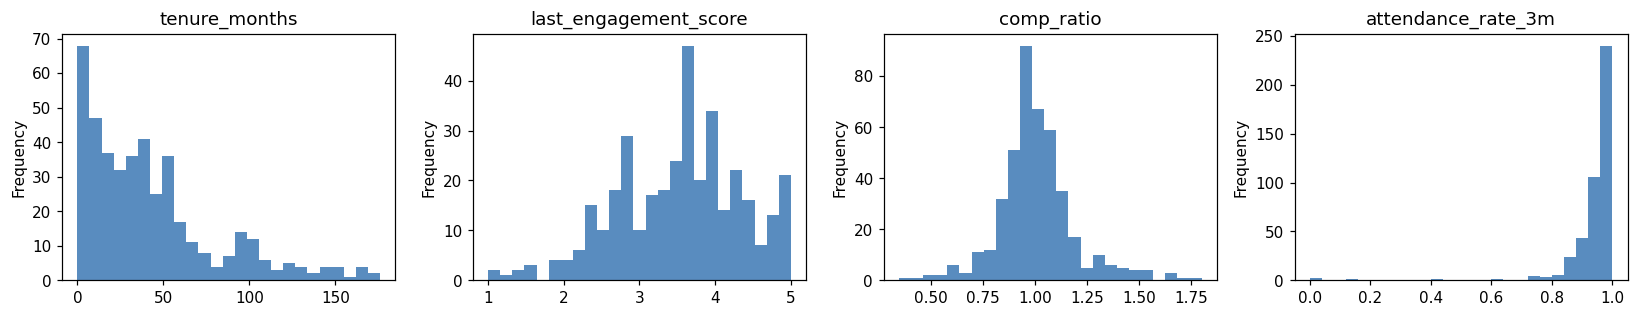

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, c in zip(ax, ['tenure_months', 'last_engagement_score', 'comp_ratio', 'attendance_rate_3m']): X[c].plot.hist(ax=a, bins=25, color='#2f6fb0', alpha=.8, label='scoring'); a.set_title(c)
plt.tight_layout()

## Stage 16: Bivariate Analysis

*What this stage is for:* Two variables together, especially against the target or label.

No label exists for the scoring set, so a bivariate view uses the model score itself (below, after scoring).

In [14]:
model = joblib.load(P.MODELS / 'attrition_v2.joblib'); p = model.predict_proba(X)[:, 1]
print('score summary:', pd.Series(p).describe().round(3).to_dict())
print('Spearman of score with: engagement %.2f | tenure %.2f | comp_ratio %.2f' % tuple(pd.Series(p).corr(X[c].reset_index(drop=True), method='spearman') for c in ['last_engagement_score', 'tenure_months', 'comp_ratio']))

score summary: {'count': 430.0, 'mean': 0.127, 'std': 0.091, 'min': 0.026, '25%': 0.058, '50%': 0.095, '75%': 0.18, 'max': 0.453}
Spearman of score with: engagement -0.55 | tenure -0.37 | comp_ratio -0.17


## Stage 17: Multivariate Analysis

*What this stage is for:* Several variables together: correlation, interaction, redundancy.

Distribution shift between training and scoring, measured with the population stability index (PSI; under 0.1 is small, over 0.25 large).

In [15]:
def psi(a, b, bins=10):
    q = np.unique(np.quantile(a.dropna(), np.linspace(0, 1, bins + 1))); q[0], q[-1] = -np.inf, np.inf
    pa = np.histogram(a.dropna(), q)[0] / a.notna().sum(); pb = np.histogram(b.dropna(), q)[0] / b.notna().sum(); pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None); return float(np.sum((pb - pa) * np.log(pb / pa)))
ps = pd.Series({c: psi(tr[c], num[c]) for c in ['tenure_months', 'last_engagement_score', 'comp_ratio', 'attendance_rate_3m', 'annual_fixed_pay', 'commute_distance_km', 'manager_changes_12m', 'job_level']}).sort_values(ascending=False); ps.round(3).to_frame('PSI')

                         PSI
attendance_rate_3m     1.475
tenure_months          0.209
annual_fixed_pay       0.160
comp_ratio             0.103
last_engagement_score  0.062
commute_distance_km    0.017
job_level              0.012
manager_changes_12m    0.001

## Stage 18: Target or Label Analysis

*What this stage is for:* How the target or human label is distributed and how reliable it is.

Not applicable to the scoring file as a label analysis: the 12-month outcome has not happened yet. What can be compared is the predicted mean risk with the historical leave rate.

In [16]:
print('mean predicted risk of the 430: %.3f | historical leave rate in training: %.3f' % (p.mean(), train['y'].mean()))

mean predicted risk of the 430: 0.127 | historical leave rate in training: 0.146


## Stage 19: Data Leakage Investigation

*What this stage is for:* Anything that carries the answer or protected information into the model.

Leakage checks for the scoring file: no exit columns; inputs identical to those of the model; and the overlap with training people.

In [17]:
from cortexhr import config as C
print('exit/outcome columns in the scoring file:', [c for c in scoring_raw.columns if c in C.FORBIDDEN_AS_INPUT and c not in ('row_id', 'employee_id', 'observation_date')] or 'none')
tr_ids = set(train['df'].employee_id); ov = scoring.employee_id.isin(tr_ids).to_numpy()
print('scoring employees that were also in the training data (earlier snapshot): %d of %d (%.0f%%)' % (ov.sum(), len(ov), ov.mean() * 100)); print('mean risk: overlap %.3f vs new people %.3f' % (p[ov].mean(), p[~ov].mean()))

exit/outcome columns in the scoring file: none
scoring employees that were also in the training data (earlier snapshot): 333 of 430 (77%)
mean risk: overlap 0.114 vs new people 0.172


Overlap is not target leakage (their 2026 outcome is unknown) but the model has seen an earlier snapshot of these people, so their scores may be slightly more confident than for strangers. It is reported, not hidden.

## Stage 20: Feature Engineering

*What this stage is for:* Build the inputs the model will use from the raw data.

Engineering for explanation: the 43 raw inputs are folded into **23 readable groups** (players). Near-duplicate columns share one player so credit is not split between them.

In [18]:
check_groups(X.columns); pd.DataFrame({'group': list(GROUPS), 'columns': [', '.join(v) for v in GROUPS.values()], 'sensitive proxy': [g in SENSITIVE_PROXY for g in GROUPS]})

                 group                                                                                                                      columns  sensitive proxy
0               tenure                                                                                                                tenure_months            False
1       career_history                                                                             total_experience_years, previous_employers_count             True
2            job_level                                                                                                                    job_level            False
3              commute                                                                                                          commute_distance_km            False
4            pay_level                                                                                                 annual_fixed_pay, comp_ratio            False
5         

## Stage 21: Feature Selection and Relevance Analysis

*What this stage is for:* Which inputs are allowed, which are relevant, which must never be used.

Sensitive-proxy groups (`career_history` can proxy for age, `education` and `work_location` for background). They stay in the model's score but are **not shown as reasons**, and their values are never printed.

In [19]:
print('groups not shown as reasons:', sorted(SENSITIVE_PROXY)); print('protected attributes (gender, age) are not model inputs:', not any(k in ' '.join(X.columns).lower() for k in ('gender', 'age_years', 'religion')))

groups not shown as reasons: ['career_history', 'education', 'work_location']
protected attributes (gender, age) are not model inputs: True


## Stage 22: Data Preprocessing

*What this stage is for:* Cleaning and encoding, fitted on training data only.

Preprocessing lives inside the saved model, so the scoring rows get exactly the training transformations. The explainer only changes raw inputs and calls the same model.

In [20]:
est = model.calibrated_classifiers_[0].estimator; print(type(model).__name__, '->', type(est).__name__, '->', [type(m).__name__ for m in est.models_], '| calibrator:', type(model.calibrated_classifiers_[0].calibrators[0]).__name__)

CalibratedClassifierCV -> BlendClassifier -> ['Pipeline', 'Pipeline'] | calibrator: _SigmoidCalibration


## Stage 23: Train, Validation and Test Strategy

*What this stage is for:* How data is split so no result is measured on data the model has seen.

No train/test split is needed for explaining a fixed model. The Shapley method needs a *reference population* (background): 200 randomly chosen labelled employees (seed 42).

In [21]:
bg = RR.build_background(); print('background rows:', len(bg))

background rows: 200


## Stage 24: Baseline Establishment

*What this stage is for:* The simple method every model must beat.

Baseline for explanations: give **everyone the same three reasons** (the globally most important groups). The local method must capture more of each person's own score movement than that.

## Stage 25: Actual SHAP library cross-check plus grouped Shapley values

Two explanation implementations are checked: the grouped Monte Carlo Shapley estimator (23 HR-readable feature groups) and the actual SHAP library PermutationExplainer on a reproducible 10-employee sample. SHAP feature contributions are also aggregated to the same HR groups for a cross-check. Both operate on the same calibrated model and background population; differences are expected because the Monte Carlo method treats related columns as grouped players while SHAP first attributes individual columns.

## Stage 26: Model Training

*What this stage is for:* Fit the candidates.

There is no model training in this task. 'Training' here means running the explainer: 120 random permutations of the 23 groups (each also run in reverse order) for all 430 employees. This takes a few minutes on one CPU.

In [22]:
import time; t = time.time(); o = RR.run_task14(write=True); print('explanation run finished in %.0f seconds' % (time.time() - t))
phi, base, fx, rep, X = o['phi'], o['base'], o['fx'], o['report'], o['X']; print('permutations:', o['n_permutations'], '(each run twice: forward and reversed)')

explanation run finished in 275 seconds
permutations: 120 (each run twice: forward and reversed)


In [30]:
# Inspect the actual SHAP library cross-check produced by RR.run_task14 above.
scx = o.get('shap_cross_check')
if scx is None:
    print('SHAP package unavailable: actual SHAP cross-check BLOCKED; grouped Monte Carlo Shapley remains active.')
else:
    print('Actual SHAP version:', scx['shap_version'])
    print('Rows:', len(scx['predictions']), '| background rows:', scx['background_rows'], '| max evaluations:', scx['max_evals'])
    print('SHAP additivity max error:', scx['additivity_max_error'])
    display(scx['group_values'].head().round(5))

Actual SHAP version: 0.50.0
Rows: 10 | background rows: 50 | max evaluations: 87
SHAP additivity max error: 2.7755575615628914e-16


## Stage 27: Cross-Validation

*What this stage is for:* Repeat the evaluation on several splits to see the spread.

Cross-validation analogue: **split-half stability**. The permutations were run as two independent halves; if the explanation is reliable the two halves should agree.

In [23]:
from cortexhr.phase3.explanations.risk_report import select_reasons
ta, tb = select_reasons(o['phi_a']), select_reasons(o['phi_b'])
ov3 = np.array([len({ta.loc[i, 'driver_1'], ta.loc[i, 'driver_2'], ta.loc[i, 'driver_3']} & {tb.loc[i, 'driver_1'], tb.loc[i, 'driver_2'], tb.loc[i, 'driver_3']}) / 3 for i in range(len(ta))])
same_top1 = (ta.driver_1 == tb.driver_1).mean()
print('correlation of contributions between halves: %.3f | same #1 reason: %.1f%% | mean overlap of the 3 shown reasons: %.2f | all three identical: %.1f%%' % (o['stability']['phi_correlation'], same_top1 * 100, ov3.mean(), (ov3 == 1).mean() * 100))

correlation of contributions between halves: 0.971 | same #1 reason: 78.8% | mean overlap of the 3 shown reasons: 0.88 | all three identical: 64.4%


## Stage 28: Hyperparameter Tuning

*What this stage is for:* A small, logged search; no tuning on the test set.

How many permutations are enough? Contributions for 40 employees with few permutations are compared with the final result.

In [24]:
sub = X.reset_index(drop=True).iloc[:40]; ref = phi.iloc[:40]; rows = []
for k in (1, 2, 4, 8):
    pk, _, _ = shapley_values(lambda d: o['model'].predict_proba(d)[:, 1], sub, o['background'], GROUPS, k, 7)
    rows.append({'permutations (x2 with reversal)': k, 'correlation with final': float(np.corrcoef(pk.to_numpy().ravel(), ref.to_numpy().ravel())[0, 1])})
conv = pd.DataFrame(rows); conv.round(3)

   permutations (x2 with reversal)  correlation with final
0                                1                   0.674
1                                2                   0.791
2                                4                   0.897
3                                8                   0.938

## Stage 29: Model Evaluation

*What this stage is for:* Metrics suited to the problem, against the baseline.

Evaluation of the explainer itself: (1) efficiency: contributions plus the baseline value must equal the prediction; (2) how much of a person's movement the three shown reasons capture, against the same-three-for-everyone baseline.

In [25]:
print('efficiency check, largest |sum(contributions) + base - prediction| over 430 employees: %.2e' % o['additivity_max_error'])
shown = [c for c in phi.columns if c not in SENSITIVE_PROXY]; A = phi[shown].clip(lower=0)
local = np.sort(A.to_numpy(), axis=1)[:, ::-1][:, :3].sum(1) / A.sum(1).replace(0, np.nan)
gtop = A.mean().sort_values(ascending=False).index[:3]; glob = A[gtop].sum(1) / A.sum(1).replace(0, np.nan)
print('share of a person\'s risk-raising movement captured by the 3 shown reasons: local %.2f vs the same global three for everyone %.2f' % (local.mean(), glob.mean())); print('global top-3 groups:', list(gtop))

efficiency check, largest |sum(contributions) + base - prediction| over 430 employees: 2.08e-16
share of a person's risk-raising movement captured by the 3 shown reasons: local 0.77 vs the same global three for everyone 0.40
global top-3 groups: ['tenure', 'job_level', 'role']


## Stage 30: Error and Misclassification Analysis

*What this stage is for:* Look at the cases the model gets wrong and say why.

Where is the explanation least reliable? Employees whose three reasons differ most between the two independent halves.

In [26]:
bad = pd.DataFrame({'employee_id': scoring.employee_id.to_numpy(), 'overlap': ov3, 'risk': np.round(p, 3)}).sort_values('overlap').head(5); print('employees with overlap <= 1/3:', int((ov3 <= 1 / 3).sum()), 'of', len(ov3)); bad

employees with overlap <= 1/3: 8 of 430


    employee_id   overlap   risk
267    EMP-0557  0.333333  0.194
273    EMP-0570  0.333333  0.045
289    EMP-0589  0.333333  0.166
286    EMP-0586  0.333333  0.192
169    EMP-0389  0.333333  0.035

Low agreement happens when several groups have almost the same small contribution, so their order is arbitrary. The shown reasons are then equally valid candidates; HR should read them as 'among the factors', not as a strict ranking.

## Stage 31: Explainability and Feature Importance

*What this stage is for:* What drives the output, in plain words.

Global view: which groups move scores most, and in which direction.

                 mean_abs_contribution
tenure                          0.0377
job_level                       0.0364
engagement                      0.0348
raises                          0.0270
manager_changes                 0.0252
role                            0.0231
career_history                  0.0211
team_context                    0.0204

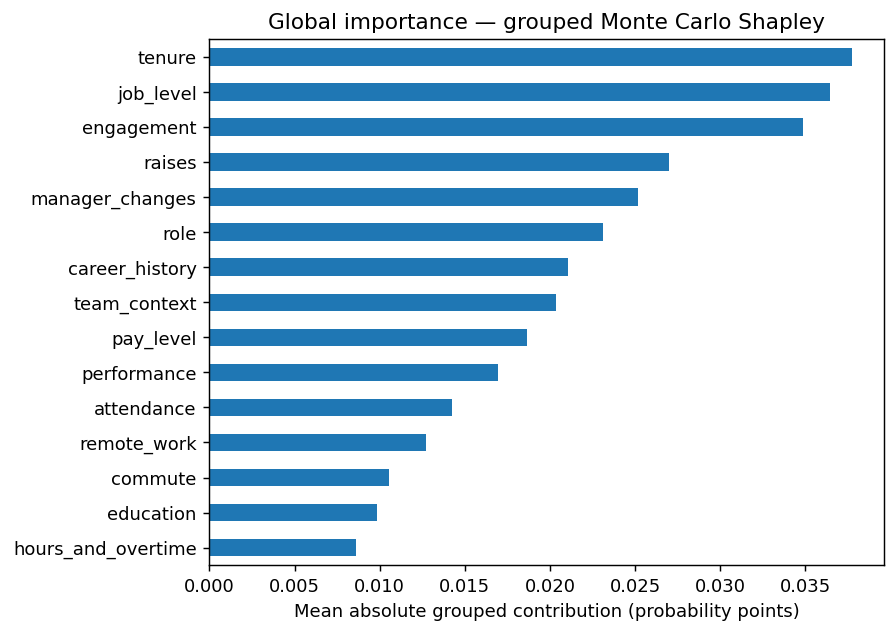

In [27]:
imp = phi.abs().mean().sort_values(ascending=False); fig, ax = plt.subplots(figsize=(7, 5)); imp.head(15)[::-1].plot.barh(ax=ax, color='#2f6fb0'); ax.set_xlabel('mean |contribution| (probability points)'); ax.set_title('Global importance of explanation groups (SHAP-style, Monte Carlo Shapley)'); plt.tight_layout(); plt.savefig(P.FIGURES / 'task14_shap_global_importance.png', dpi=130, bbox_inches='tight'); imp.head(8).round(4).to_frame('mean_abs_contribution')

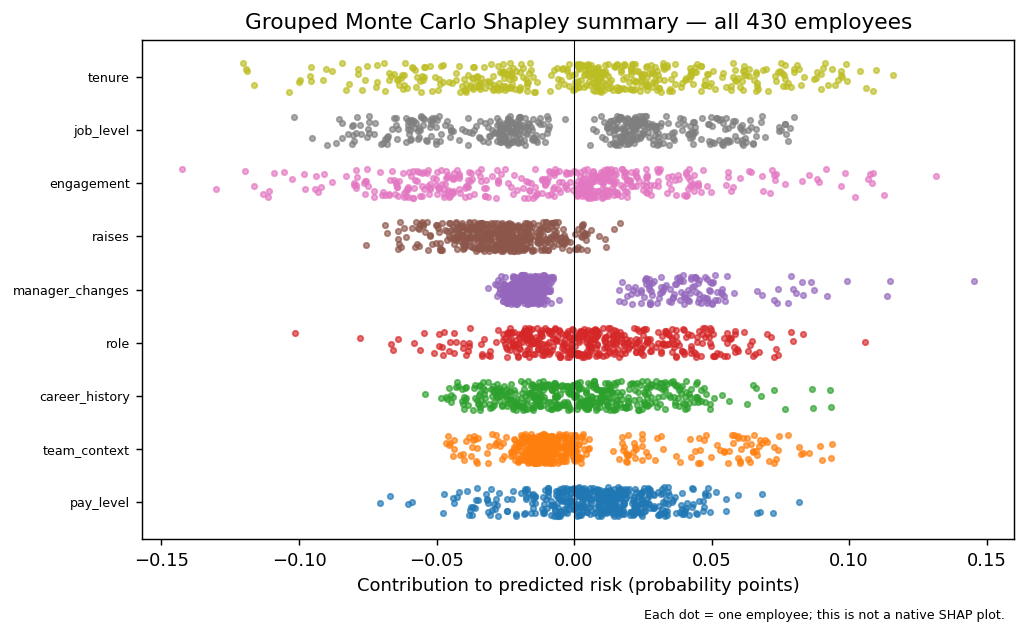

In [28]:
KEY = {'tenure': 'tenure_months', 'engagement': 'last_engagement_score', 'raises': 'months_since_last_raise', 'pay_level': 'comp_ratio', 'manager_changes': 'manager_changes_12m', 'performance': 'last_performance_rating',
       'attendance': 'attendance_rate_3m', 'team_context': 'dept_attrition_rate_prior_12m', 'job_level': 'job_level', 'commute': 'commute_distance_km', 'training': 'training_hours_12m', 'hours_and_overtime': 'avg_hours_worked_3m'}
top = [g for g in imp.index if g in KEY][:9]; fig, ax = plt.subplots(figsize=(8, 5)); rng = np.random.default_rng(SEED); Xr = X.reset_index(drop=True)
for k, g in enumerate(top[::-1]):
    v = Xr[KEY[g]].rank(pct=True).fillna(.5).to_numpy(); sc_ = ax.scatter(phi[g], k + rng.uniform(-.28, .28, len(phi)), c=v, cmap='coolwarm', s=9)
ax.set_yticks(range(len(top))); ax.set_yticklabels([f'{g} ({KEY[g]})' for g in top[::-1]], fontsize=7); ax.axvline(0, color='k', lw=.6); ax.set_xlabel('contribution to risk (probability points)'); plt.colorbar(sc_, label='feature value (low to high)'); ax.set_title('Grouped Monte Carlo Shapley summary (all 430 employees)'); plt.tight_layout(); plt.savefig(P.FIGURES / 'task14_shap_summary.png', dpi=130, bbox_inches='tight')

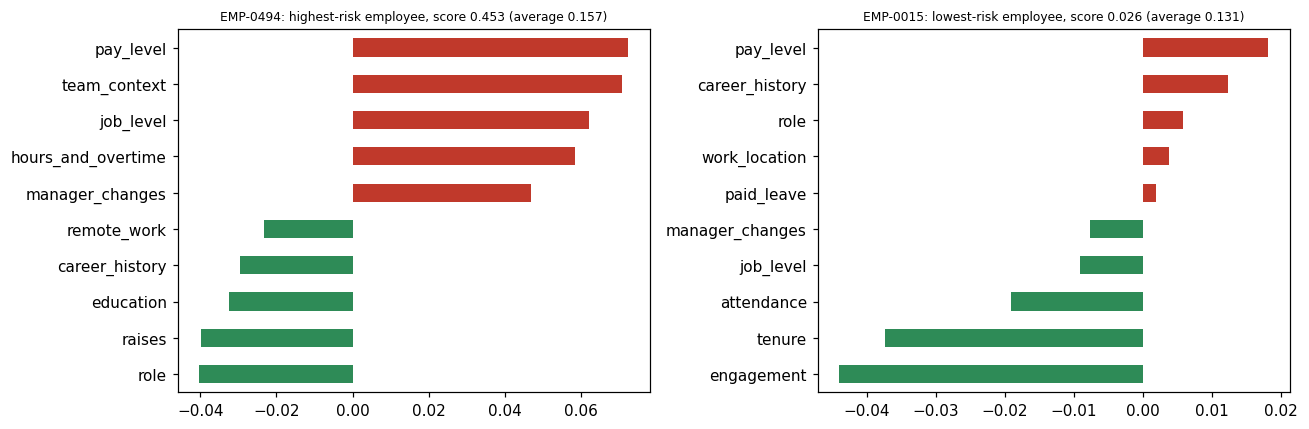

In [29]:
i_hi, i_lo = int(np.argmax(p)), int(np.argmin(p)); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, i, t in zip(ax, (i_hi, i_lo), ('highest-risk employee', 'lowest-risk employee')):
    s = phi.iloc[i].sort_values(); s = pd.concat([s.head(5), s.tail(5)]); s.plot.barh(ax=a, color=['#2e8b57' if v < 0 else '#c0392b' for v in s]); a.set_title(f'{scoring.employee_id.iloc[i]}: {t}, score {p[i]:.3f} (average {base.iloc[i]:.3f})', fontsize=8)
plt.tight_layout()